# Experiment 1 — Best Frequency-Scout Slice Selection (Cardiac MRI SAX @ 3.0T)

**Goal:** Train CNNs to pick the best frequency-scout slice per patient (ground truth: manual `image no` in the cohort Excel), and report **Top-1** and **Top-3** accuracy on a held-out patient test set.

**Data:** 26 patients, mostly 13 DICOM slices each (variable count for a few cases).

**Approach:** Per-slice quality scoring with soft labels peaked at the GT slice → at inference, rank a patient's slices by predicted score and take Top-1 / Top-3.

**Models compared:** Lightweight custom CNN · ResNet18 · EfficientNet-B0 (ImageNet transfer).

**Runtime:** GPU recommended on Kaggle (`Accelerator → GPU T4`). With ~300 images this also runs on a laptop CPU (slower, ~10–30 min).

### Kaggle setup
1. Create a Dataset containing:
   - `Dr-Dataset/1st_cohort_SAX/Patient-*/img*.dcm`
   - `1stcohortSAX (1).xlsx` (or rename to `1stcohortSAX.xlsx`)
2. Add that dataset to this notebook.
3. Enable GPU if available, then Run All.

## 0. Install dependencies

In [1]:
# On Kaggle, torch/torchvision are usually preinstalled with GPU wheels.
# Locally this will install any missing packages.

import subprocess, sys

def _ensure(pkgs):
    missing = []
    for p, import_name in pkgs:
        try:
            __import__(import_name)
        except ImportError:
            missing.append(p)
    if missing:
        print("Installing:", missing)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

_ensure([
    ("pydicom", "pydicom"),
    ("openpyxl", "openpyxl"),
    ("pandas", "pandas"),
    ("scikit-learn", "sklearn"),
    ("matplotlib", "matplotlib"),
    ("seaborn", "seaborn"),
    ("tqdm", "tqdm"),
    ("pillow", "PIL"),
    ("torch", "torch"),
    ("torchvision", "torchvision"),
])
print("Dependencies OK")


Dependencies OK


## 1. Config & paths (Kaggle + local)

In [2]:
from __future__ import annotations

import os
import random
import json
from pathlib import Path
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import pydicom
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms as T
from torchvision import models

from sklearn.model_selection import train_test_split, StratifiedKFold
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)

# ---------- paths ----------
IS_KAGGLE = Path("/kaggle/input").exists()


def find_excel(root: Path) -> Path:
    patterns = ["**/1stcohortSAX*.xlsx", "**/*cohort*SAX*.xlsx", "**/*SAX*.xlsx"]
    for pat in patterns:
        hits = sorted(root.glob(pat))
        preferred = [h for h in hits if "cohort" in h.name.lower() or "1st" in h.name.lower()]
        pool = preferred or hits
        if pool:
            return pool[0]
    raise FileNotFoundError(f"No cohort Excel found under {root}")


def find_dicom_root(root: Path) -> Path:
    hits = list(root.rglob("1st_cohort_SAX"))
    if hits:
        return hits[0]
    pats = [p for p in root.rglob("Patient-*") if p.is_dir()]
    if pats:
        return pats[0].parent
    raise FileNotFoundError(f"No 1st_cohort_SAX / Patient-* folders under {root}")


if IS_KAGGLE:
    INPUT_ROOT = Path("/kaggle/input")
    DATA_ROOT = None
    for c in sorted(INPUT_ROOT.iterdir()):
        try:
            find_dicom_root(c)
            DATA_ROOT = c
            break
        except FileNotFoundError:
            continue
    if DATA_ROOT is None:
        DATA_ROOT = next(INPUT_ROOT.iterdir())
    OUT_DIR = Path("/kaggle/working/exp1_outputs")
else:
    DATA_ROOT = Path(".").resolve()
    OUT_DIR = DATA_ROOT / "exp1_outputs"

OUT_DIR.mkdir(parents=True, exist_ok=True)

EXCEL_PATH = find_excel(DATA_ROOT)
DICOM_ROOT = find_dicom_root(DATA_ROOT)

print(f"IS_KAGGLE   = {IS_KAGGLE}")
print(f"DATA_ROOT   = {DATA_ROOT}")
print(f"EXCEL_PATH  = {EXCEL_PATH}")
print(f"DICOM_ROOT  = {DICOM_ROOT}")
print(f"OUT_DIR     = {OUT_DIR}")


IS_KAGGLE   = True
DATA_ROOT   = /kaggle/input/datasets
EXCEL_PATH  = /kaggle/input/datasets/muhammadmoazzamimran/dr-usmancardiodataset/1stcohortSAX (1).xlsx
DICOM_ROOT  = /kaggle/input/datasets/muhammadmoazzamimran/dr-usmancardiodataset/Dr-Dataset/1st_cohort_SAX
OUT_DIR     = /kaggle/working/exp1_outputs


In [3]:
@dataclass
class CFG:
    seed: int = 42
    img_size: int = 224
    batch_size: int = 16
    num_workers: int = 0          # 0 is safest on Windows / notebooks
    epochs: int = 40
    lr: float = 1e-4
    weight_decay: float = 1e-4
    test_size: float = 0.25       # ~6–7 patients held out
    soft_label_sigma: float = 1.0 # soft peak width around GT slice
    early_stop_patience: int = 10
    models_to_train: tuple = ("simple_cnn", "resnet18", "efficientnet_b0")  # on CPU laptop prefer ("simple_cnn",) or ("resnet18",)
    use_kfold: bool = False       # set True for leave-ish CV (slower)
    n_folds: int = 5
    device: str = "cuda" if torch.cuda.is_available() else "cpu"

cfg = CFG()

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(cfg.seed)
DEVICE = torch.device(cfg.device)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print(json.dumps(asdict(cfg), indent=2))

Device: cuda
GPU: Tesla T4
{
  "seed": 42,
  "img_size": 224,
  "batch_size": 16,
  "num_workers": 0,
  "epochs": 40,
  "lr": 0.0001,
  "weight_decay": 0.0001,
  "test_size": 0.25,
  "soft_label_sigma": 1.0,
  "early_stop_patience": 10,
  "models_to_train": [
    "simple_cnn",
    "resnet18",
    "efficientnet_b0"
  ],
  "use_kfold": false,
  "n_folds": 5,
  "device": "cuda"
}


## 2. Load ground truth & index DICOMs

In [4]:
def load_labels(excel_path: Path) -> pd.DataFrame:
    raw = pd.read_excel(excel_path, header=None)
    # Find header row containing 'Anonymized ID'
    header_idx = None
    for i, row in raw.iterrows():
        vals = [str(v).strip() if pd.notna(v) else "" for v in row.tolist()]
        if "Anonymized ID" in vals:
            header_idx = i
            break
    if header_idx is None:
        raise ValueError("Could not find header row with 'Anonymized ID'")

    df = pd.read_excel(excel_path, header=header_idx)
    # Drop fully-empty leading columns from sheet layout
    df = df.dropna(axis=1, how="all")
    df = df.dropna(subset=["Anonymized ID"]).reset_index(drop=True)
    df = df.rename(columns={
        "Anonymized ID": "patient_id",
        "Plane": "plane",
        "Max Freq (Hz)": "max_freq",
        "Freq Step (Hz)": "freq_step",
        "Min Freq (Hz)": "min_freq",
        "Manual frequency (Hz)": "manual_freq",
        "image no": "gt_image_no",
    })
    df["gt_image_no"] = df["gt_image_no"].astype(int)
    return df

labels_df = load_labels(EXCEL_PATH)
print(labels_df.to_string(index=False))
print("\nPatients:", len(labels_df))

  patient_id plane  max_freq  freq_step  min_freq  manual_freq  gt_image_no
 Patient-BEV   SAX       150         25      -150            0            7
 Patient-BGT   SAX       150         25      -150            0            7
 Patient-BVE   SAX       150         25      -150           25            6
 Patient-CEA   SAX       150         25      -150            0            7
Patient-CEJP   SAX       150         25      -150           75            4
 Patient-DEM   SAX       150         25      -150          -50            9
 Patient-FAJ   SAX       150         25      -150          -50            9
 Patient-FEC   SAX       150         25      -150          -25            8
  Patient-GJ   SAX       150         25      -150          -50            9
 Patient-HMJ   SAX       150         25      -150          -25            8
 Patient-HRJ   SAX       150         25      -150            0            7
 Patient-IAM   SAX       150         25      -150          -25            8
 Patient-INA

In [5]:
def parse_instance_from_name(path: Path) -> int | None:
    # img0007-57.5835_anon.dcm → 7
    name = path.name
    if name.lower().startswith("img"):
        digits = ""
        for ch in name[3:]:
            if ch.isdigit():
                digits += ch
            else:
                break
        return int(digits) if digits else None
    return None


def build_slice_index(dicom_root: Path, labels: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for _, lab in labels.iterrows():
        pid = lab["patient_id"]
        pdir = dicom_root / pid
        if not pdir.exists():
            # try case-insensitive match
            matches = [d for d in dicom_root.iterdir() if d.is_dir() and d.name.lower() == pid.lower()]
            if not matches:
                print(f"WARNING: missing folder for {pid}")
                continue
            pdir = matches[0]

        dcms = sorted(pdir.glob("*.dcm"))
        for f in dcms:
            inst = parse_instance_from_name(f)
            if inst is None:
                try:
                    ds = pydicom.dcmread(f, stop_before_pixels=True)
                    inst = int(getattr(ds, "InstanceNumber", 0))
                except Exception:
                    continue
            dist = abs(inst - int(lab["gt_image_no"]))
            soft = float(np.exp(-0.5 * (dist / cfg.soft_label_sigma) ** 2))
            rows.append({
                "patient_id": pid,
                "path": str(f),
                "instance_no": inst,
                "gt_image_no": int(lab["gt_image_no"]),
                "manual_freq": lab["manual_freq"],
                "freq_step": lab["freq_step"],
                "is_best": int(inst == int(lab["gt_image_no"])),
                "soft_label": soft,
                "abs_dist": dist,
            })
    return pd.DataFrame(rows)


index_df = build_slice_index(DICOM_ROOT, labels_df)
print(index_df.groupby("patient_id").size().rename("n_slices").to_string())
print("\nTotal slices:", len(index_df))
print("Best-slice present for all patients?",
      index_df.groupby("patient_id")["is_best"].sum().eq(1).all())
display(index_df.head(10))

patient_id
Patient-BEV     13
Patient-BGT     13
Patient-BVE     12
Patient-CEA     13
Patient-CEJP    13
Patient-DEM     13
Patient-FAJ     13
Patient-FEC     13
Patient-GJ      13
Patient-HMJ     13
Patient-HRJ     13
Patient-IAM     13
Patient-INA     13
Patient-KP       7
Patient-MJ      13
Patient-MS      13
Patient-MSR     13
Patient-OAF     13
Patient-PJ      13
Patient-RAK     13
Patient-RK      13
Patient-SK      13
Patient-SWJ     13
Patient-TL      13
Patient-WBC     13
Patient-WMR     13

Total slices: 331
Best-slice present for all patients? True


,patient_id,path,instance_no,gt_image_no,manual_freq,freq_step,is_best,soft_label,abs_dist
0,Patient-BEV,/kaggle/input/datasets/muhammadmoazzamimran/dr...,1,7,0,25,0,1.522998e-08,6
1,Patient-BEV,/kaggle/input/datasets/muhammadmoazzamimran/dr...,2,7,0,25,0,3.726653e-06,5
2,Patient-BEV,/kaggle/input/datasets/muhammadmoazzamimran/dr...,3,7,0,25,0,3.354626e-04,4
3,Patient-BEV,/kaggle/input/datasets/muhammadmoazzamimran/dr...,4,7,0,25,0,1.110900e-02,3
4,Patient-BEV,/kaggle/input/datasets/muhammadmoazzamimran/dr...,5,7,0,25,0,1.353353e-01,2
5,Patient-BEV,/kaggle/input/datasets/muhammadmoazzamimran/dr...,6,7,0,25,0,6.065307e-01,1
6,Patient-BEV,/kaggle/input/datasets/muhammadmoazzamimran/dr...,7,7,0,25,1,1.000000e+00,0
7,Patient-BEV,/kaggle/input/datasets/muhammadmoazzamimran/dr...,8,7,0,25,0,6.065307e-01,1
8,Patient-BEV,/kaggle/input/datasets/muhammadmoazzamimran/dr...,9,7,0,25,0,1.353353e-01,2
9,Patient-BEV,/kaggle/input/datasets/muhammadmoazzamimran/dr...,10,7,0,25,0,1.110900e-02,3


## 3. Quick EDA

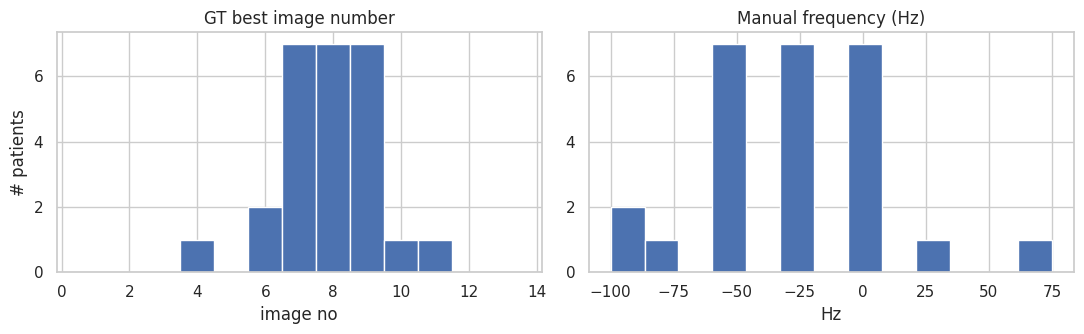

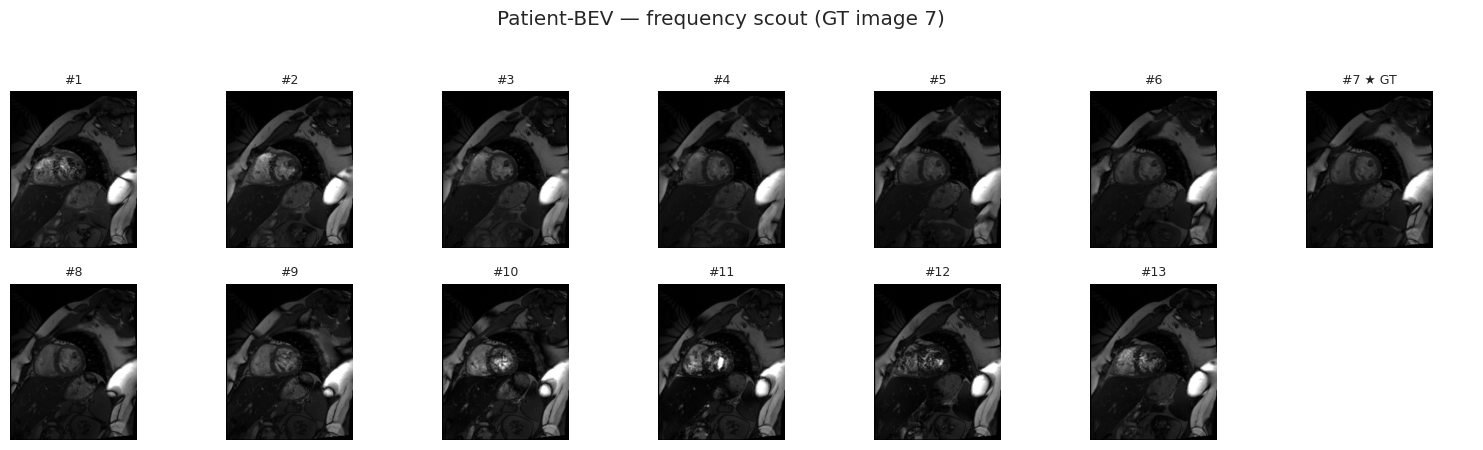

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

axes[0].hist(labels_df["gt_image_no"], bins=np.arange(0.5, 14.5, 1), edgecolor="white")
axes[0].set_title("GT best image number")
axes[0].set_xlabel("image no")
axes[0].set_ylabel("# patients")

axes[1].hist(labels_df["manual_freq"], bins=13, edgecolor="white")
axes[1].set_title("Manual frequency (Hz)")
axes[1].set_xlabel("Hz")

plt.tight_layout()
plt.show()

# Show one patient's frequency scout stack
demo_pid = labels_df.iloc[0]["patient_id"]
demo = index_df[index_df["patient_id"] == demo_pid].sort_values("instance_no")
gt = int(demo["gt_image_no"].iloc[0])

n = len(demo)
cols = min(7, n)
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.2 * rows))
axes = np.array(axes).reshape(-1)
for ax, (_, r) in zip(axes, demo.iterrows()):
    arr = pydicom.dcmread(r["path"]).pixel_array.astype(np.float32)
    p1, p99 = np.percentile(arr, (1, 99))
    arr = np.clip((arr - p1) / max(p99 - p1, 1e-6), 0, 1)
    ax.imshow(arr, cmap="gray")
    title = f"#{int(r['instance_no'])}"
    if r["is_best"]:
        title += " ★ GT"
        for spine in ax.spines.values():
            spine.set_color("lime")
            spine.set_linewidth(2)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
for ax in axes[n:]:
    ax.axis("off")
fig.suptitle(f"{demo_pid} — frequency scout (GT image {gt})", y=1.02)
plt.tight_layout()
plt.show()

## 4. Patient-level train / test split

Slices from the same patient never appear in both train and test.

In [7]:
patients = labels_df["patient_id"].tolist()
# Stratify by binned GT image no so both splits see similar best-slice positions
strata = pd.qcut(labels_df["gt_image_no"], q=min(3, len(patients) // 3), duplicates="drop").astype(str)

train_pids, test_pids = train_test_split(
    patients,
    test_size=cfg.test_size,
    random_state=cfg.seed,
    stratify=strata,
)

train_df = index_df[index_df["patient_id"].isin(train_pids)].reset_index(drop=True)
test_df = index_df[index_df["patient_id"].isin(test_pids)].reset_index(drop=True)

# Small validation from training patients for early stopping
train_pids2, val_pids = train_test_split(
    train_pids, test_size=0.2, random_state=cfg.seed
)
fit_df = index_df[index_df["patient_id"].isin(train_pids2)].reset_index(drop=True)
val_df = index_df[index_df["patient_id"].isin(val_pids)].reset_index(drop=True)

print(f"Train patients ({len(train_pids2)}): {sorted(train_pids2)}")
print(f"Val   patients ({len(val_pids)}): {sorted(val_pids)}")
print(f"Test  patients ({len(test_pids)}): {sorted(test_pids)}")
print(f"Slices — fit:{len(fit_df)}  val:{len(val_df)}  test:{len(test_df)}")

Train patients (15): ['Patient-BEV', 'Patient-BGT', 'Patient-BVE', 'Patient-DEM', 'Patient-FAJ', 'Patient-FEC', 'Patient-HRJ', 'Patient-MJ', 'Patient-MS', 'Patient-MSR', 'Patient-OAF', 'Patient-PJ', 'Patient-RAK', 'Patient-SWJ', 'Patient-WBC']
Val   patients (4): ['Patient-GJ', 'Patient-HMJ', 'Patient-INA', 'Patient-SK']
Test  patients (7): ['Patient-CEA', 'Patient-CEJP', 'Patient-IAM', 'Patient-KP', 'Patient-RK', 'Patient-TL', 'Patient-WMR']
Slices — fit:194  val:52  test:85


## 5. Dataset & dataloaders

In [8]:
def load_dicom_image(path: str) -> np.ndarray:
    ds = pydicom.dcmread(path)
    arr = ds.pixel_array.astype(np.float32)
    # Percentile windowing → robust contrast across patients
    p1, p99 = np.percentile(arr, (1, 99))
    arr = np.clip((arr - p1) / max(p99 - p1, 1e-6), 0, 1)
    return arr


class SliceQualityDataset(Dataset):
    """Each item is one scout slice with a soft quality target in [0, 1]."""

    def __init__(self, frame: pd.DataFrame, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        img = load_dicom_image(row["path"])          # HxW float32 [0,1]
        img = (img * 255).astype(np.uint8)
        img = Image.fromarray(img).convert("RGB")    # 3ch for torchvision backbones
        if self.transform:
            img = self.transform(img)
        target = torch.tensor(row["soft_label"], dtype=torch.float32)
        meta = {
            "patient_id": row["patient_id"],
            "instance_no": int(row["instance_no"]),
            "gt_image_no": int(row["gt_image_no"]),
            "is_best": int(row["is_best"]),
        }
        return img, target, meta


IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.Resize((cfg.img_size, cfg.img_size)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=8, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    T.ColorJitter(brightness=0.15, contrast=0.15),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tf = T.Compose([
    T.Resize((cfg.img_size, cfg.img_size)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def make_loaders(fit: pd.DataFrame, val: pd.DataFrame, test: pd.DataFrame):
    ds_fit = SliceQualityDataset(fit, train_tf)
    ds_val = SliceQualityDataset(val, eval_tf)
    ds_test = SliceQualityDataset(test, eval_tf)
    kw = dict(num_workers=cfg.num_workers, pin_memory=(DEVICE.type == "cuda"))
    return (
        DataLoader(ds_fit, batch_size=cfg.batch_size, shuffle=True, **kw),
        DataLoader(ds_val, batch_size=cfg.batch_size, shuffle=False, **kw),
        DataLoader(ds_test, batch_size=cfg.batch_size, shuffle=False, **kw),
    )


train_loader, val_loader, test_loader = make_loaders(fit_df, val_df, test_df)
xb, yb, mb = next(iter(train_loader))
print("Batch:", xb.shape, yb.shape, "patients sample:", mb["patient_id"][:3])

Batch: torch.Size([16, 3, 224, 224]) torch.Size([16]) patients sample: ['Patient-WBC', 'Patient-HRJ', 'Patient-WBC']


## 6. Models

In [9]:
class SimpleCNN(nn.Module):
    """Small CNN baseline — fast on CPU."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)


def build_model(name: str) -> nn.Module:
    name = name.lower()
    if name == "simple_cnn":
        return SimpleCNN()

    if name == "resnet18":
        try:
            weights = models.ResNet18_Weights.IMAGENET1K_V1
            m = models.resnet18(weights=weights)
        except Exception:
            m = models.resnet18(pretrained=True)
        m.fc = nn.Linear(m.fc.in_features, 1)
        return m

    if name == "efficientnet_b0":
        try:
            weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
            m = models.efficientnet_b0(weights=weights)
        except Exception:
            m = models.efficientnet_b0(pretrained=True)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 1)
        return m

    raise ValueError(f"Unknown model: {name}")


def forward_score(model: nn.Module, x: torch.Tensor) -> torch.Tensor:
    """Return unbounded score; sigmoid applied for soft-label BCE."""
    out = model(x)
    if out.ndim > 1:
        out = out.squeeze(-1)
    return out


# Sanity check
for n in cfg.models_to_train:
    m = build_model(n).to(DEVICE)
    with torch.no_grad():
        s = forward_score(m, xb.to(DEVICE))
    print(f"{n:20s} params={sum(p.numel() for p in m.parameters()):,}  out={tuple(s.shape)}")
    del m
    torch.cuda.empty_cache() if DEVICE.type == "cuda" else None

simple_cnn           params=405,889  out=(16,)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 211MB/s]


resnet18             params=11,177,025  out=(16,)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 180MB/s]


efficientnet_b0      params=4,008,829  out=(16,)


## 7. Training & patient-level metrics

For each patient we rank slices by predicted quality score:
- **Top-1 accuracy:** predicted best instance == GT `image no`
- **Top-3 accuracy:** GT instance is among the 3 highest-scoring slices
- **MAE:** |predicted best − GT| in slice index units

In [10]:
@torch.no_grad()
def predict_frame(model: nn.Module, frame: pd.DataFrame, transform) -> pd.DataFrame:
    model.eval()
    ds = SliceQualityDataset(frame, transform)
    loader = DataLoader(ds, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers)
    scores, pids, insts, gts = [], [], [], []
    for x, _, meta in loader:
        x = x.to(DEVICE)
        logit = forward_score(model, x)
        scores.extend(torch.sigmoid(logit).cpu().numpy().tolist())
        pids.extend(meta["patient_id"])
        insts.extend([int(v) for v in meta["instance_no"]])
        gts.extend([int(v) for v in meta["gt_image_no"]])
    return pd.DataFrame({
        "patient_id": pids,
        "instance_no": insts,
        "gt_image_no": gts,
        "score": scores,
    })


def patient_ranking_metrics(pred_df: pd.DataFrame) -> dict:
    top1, top3, maes, records = [], [], [], []
    for pid, g in pred_df.groupby("patient_id"):
        g = g.sort_values("score", ascending=False)
        gt = int(g["gt_image_no"].iloc[0])
        ranked = g["instance_no"].tolist()
        pred1 = int(ranked[0])
        hit1 = int(pred1 == gt)
        hit3 = int(gt in ranked[: min(3, len(ranked))])
        mae = abs(pred1 - gt)
        top1.append(hit1); top3.append(hit3); maes.append(mae)
        records.append({
            "patient_id": pid,
            "gt_image_no": gt,
            "pred_top1": pred1,
            "pred_top3": ranked[:3],
            "top1_correct": hit1,
            "top3_correct": hit3,
            "mae": mae,
        })
    return {
        "top1_acc": float(np.mean(top1)) if top1 else 0.0,
        "top3_acc": float(np.mean(top3)) if top3 else 0.0,
        "mae": float(np.mean(maes)) if maes else 0.0,
        "n_patients": len(top1),
        "per_patient": pd.DataFrame(records),
    }


def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    losses = []
    for x, y, _ in loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)
        with torch.set_grad_enabled(train):
            logit = forward_score(model, x)
            loss = F.binary_cross_entropy_with_logits(logit, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
        losses.append(loss.item())
    return float(np.mean(losses))


def train_one_model(model_name: str, fit: pd.DataFrame, val: pd.DataFrame, tag: str = ""):
    print("\n" + "=" * 60)
    print(f"Training: {model_name} {tag}")
    print("=" * 60)

    model = build_model(model_name).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.epochs)

    tr_loader, va_loader, _ = make_loaders(fit, val, val)

    best_val = -1.0
    best_state = None
    patience = 0
    history = []

    for epoch in range(1, cfg.epochs + 1):
        tr_loss = run_epoch(model, tr_loader, opt)
        va_loss = run_epoch(model, va_loader, optimizer=None)
        sched.step()

        pred = predict_frame(model, val, eval_tf)
        metrics = patient_ranking_metrics(pred)
        history.append({
            "epoch": epoch,
            "train_loss": tr_loss,
            "val_loss": va_loss,
            "val_top1": metrics["top1_acc"],
            "val_top3": metrics["top3_acc"],
            "val_mae": metrics["mae"],
        })

        # Early-stop on Top-3 (primary clinical usefulness), then Top-1
        score = metrics["top3_acc"] + 0.1 * metrics["top1_acc"]
        improved = score > best_val + 1e-6
        if improved:
            best_val = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience = 0
        else:
            patience += 1

        if epoch == 1 or epoch % 5 == 0 or improved:
            print(
                f"Epoch {epoch:02d}/{cfg.epochs}  "
                f"tr={tr_loss:.4f} va={va_loss:.4f}  "
                f"Top1={metrics['top1_acc']:.3f} Top3={metrics['top3_acc']:.3f} "
                f"MAE={metrics['mae']:.2f}"
                + ("  *best*" if improved else "")
            )

        if patience >= cfg.early_stop_patience:
            print(f"Early stopping at epoch {epoch}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    ckpt = OUT_DIR / f"{model_name}{('_' + tag) if tag else ''}_best.pt"
    torch.save({"model": model.state_dict(), "cfg": asdict(cfg), "name": model_name}, ckpt)
    hist_df = pd.DataFrame(history)
    hist_df.to_csv(OUT_DIR / f"{model_name}{('_' + tag) if tag else ''}_history.csv", index=False)
    print("Saved:", ckpt)
    return model, hist_df

## 8. Train all models & evaluate on test patients

In [11]:
results = []
histories = {}
per_patient_tables = {}
trained_models = {}

for model_name in cfg.models_to_train:
    model, hist = train_one_model(model_name, fit_df, val_df)
    histories[model_name] = hist
    trained_models[model_name] = model

    # Evaluate on held-out test patients
    pred_test = predict_frame(model, test_df, eval_tf)
    metrics = patient_ranking_metrics(pred_test)
    per_patient_tables[model_name] = metrics["per_patient"]

    results.append({
        "model": model_name,
        "test_top1_acc": metrics["top1_acc"],
        "test_top3_acc": metrics["top3_acc"],
        "test_mae": metrics["mae"],
        "n_test_patients": metrics["n_patients"],
    })

    print(f"\n>>> {model_name} TEST  Top-1={metrics['top1_acc']:.3f}  "
          f"Top-3={metrics['top3_acc']:.3f}  MAE={metrics['mae']:.2f}")
    display(metrics["per_patient"])

results_df = pd.DataFrame(results).sort_values("test_top3_acc", ascending=False)
results_df.to_csv(OUT_DIR / "experiment1_test_results.csv", index=False)
print("\n=== Experiment 1 summary (test set) ===")
display(results_df)


Training: simple_cnn 
Epoch 01/40  tr=0.6369 va=0.6242  Top1=0.000 Top3=0.500 MAE=5.00  *best*
Epoch 02/40  tr=0.5882 va=0.5822  Top1=0.500 Top3=0.750 MAE=1.00  *best*
Epoch 05/40  tr=0.5318 va=0.4814  Top1=0.000 Top3=0.500 MAE=3.25
Epoch 10/40  tr=0.4921 va=0.4480  Top1=0.000 Top3=0.000 MAE=3.00
Early stopping at epoch 12
Saved: /kaggle/working/exp1_outputs/simple_cnn_best.pt

>>> simple_cnn TEST  Top-1=0.000  Top-3=0.000  MAE=4.57


,patient_id,gt_image_no,pred_top1,pred_top3,top1_correct,top3_correct,mae
0,Patient-CEA,7,1,"[1, 6, 9]",0,0,6
1,Patient-CEJP,4,6,"[6, 1, 3]",0,0,2
2,Patient-IAM,8,1,"[1, 12, 9]",0,0,7
3,Patient-KP,6,5,"[5, 4, 1]",0,0,1
4,Patient-RK,9,1,"[1, 3, 4]",0,0,8
5,Patient-TL,9,7,"[7, 2, 8]",0,0,2
6,Patient-WMR,8,2,"[2, 1, 13]",0,0,6



Training: resnet18 
Epoch 01/40  tr=0.8023 va=0.5242  Top1=0.250 Top3=0.250 MAE=0.75  *best*
Epoch 02/40  tr=0.5509 va=0.4617  Top1=0.250 Top3=0.500 MAE=1.25  *best*
Epoch 04/40  tr=0.3334 va=0.3904  Top1=0.250 Top3=0.750 MAE=1.00  *best*
Epoch 05/40  tr=0.3235 va=0.3955  Top1=0.250 Top3=0.500 MAE=1.00
Epoch 10/40  tr=0.3904 va=0.4337  Top1=0.250 Top3=0.250 MAE=2.00
Epoch 12/40  tr=0.2871 va=0.4182  Top1=0.250 Top3=1.000 MAE=1.50  *best*
Epoch 15/40  tr=0.2585 va=0.3799  Top1=0.250 Top3=0.750 MAE=1.50
Epoch 19/40  tr=0.2420 va=0.3606  Top1=0.500 Top3=1.000 MAE=0.75  *best*
Epoch 20/40  tr=0.2362 va=0.3753  Top1=0.500 Top3=1.000 MAE=0.75
Epoch 25/40  tr=0.2323 va=0.3923  Top1=0.500 Top3=0.750 MAE=0.75
Early stopping at epoch 29
Saved: /kaggle/working/exp1_outputs/resnet18_best.pt

>>> resnet18 TEST  Top-1=0.143  Top-3=0.714  MAE=1.00


,patient_id,gt_image_no,pred_top1,pred_top3,top1_correct,top3_correct,mae
0,Patient-CEA,7,6,"[6, 7, 10]",0,1,1
1,Patient-CEJP,4,4,"[4, 6, 2]",1,1,0
2,Patient-IAM,8,10,"[10, 7, 8]",0,1,2
3,Patient-KP,6,7,"[7, 5, 6]",0,1,1
4,Patient-RK,9,8,"[8, 7, 6]",0,0,1
5,Patient-TL,9,8,"[8, 7, 9]",0,1,1
6,Patient-WMR,8,7,"[7, 6, 4]",0,0,1



Training: efficientnet_b0 
Epoch 01/40  tr=0.6403 va=0.5863  Top1=0.500 Top3=0.750 MAE=1.00  *best*
Epoch 03/40  tr=0.4727 va=0.5145  Top1=0.750 Top3=1.000 MAE=0.25  *best*
Epoch 04/40  tr=0.3836 va=0.4836  Top1=1.000 Top3=1.000 MAE=0.00  *best*
Epoch 05/40  tr=0.3328 va=0.3720  Top1=0.500 Top3=1.000 MAE=0.50
Epoch 10/40  tr=0.2768 va=0.3074  Top1=0.500 Top3=1.000 MAE=0.50
Early stopping at epoch 14
Saved: /kaggle/working/exp1_outputs/efficientnet_b0_best.pt

>>> efficientnet_b0 TEST  Top-1=0.286  Top-3=0.571  MAE=1.29


,patient_id,gt_image_no,pred_top1,pred_top3,top1_correct,top3_correct,mae
0,Patient-CEA,7,6,"[6, 7, 5]",0,1,1
1,Patient-CEJP,4,4,"[4, 7, 3]",1,1,0
2,Patient-IAM,8,8,"[8, 10, 7]",1,1,0
3,Patient-KP,6,3,"[3, 6, 2]",0,1,3
4,Patient-RK,9,7,"[7, 6, 4]",0,0,2
5,Patient-TL,9,10,"[10, 5, 8]",0,0,1
6,Patient-WMR,8,6,"[6, 9, 5]",0,0,2



=== Experiment 1 summary (test set) ===


,model,test_top1_acc,test_top3_acc,test_mae,n_test_patients
1,resnet18,0.142857,0.714286,1.000000,7
2,efficientnet_b0,0.285714,0.571429,1.285714,7
0,simple_cnn,0.000000,0.000000,4.571429,7


## 9. Plots

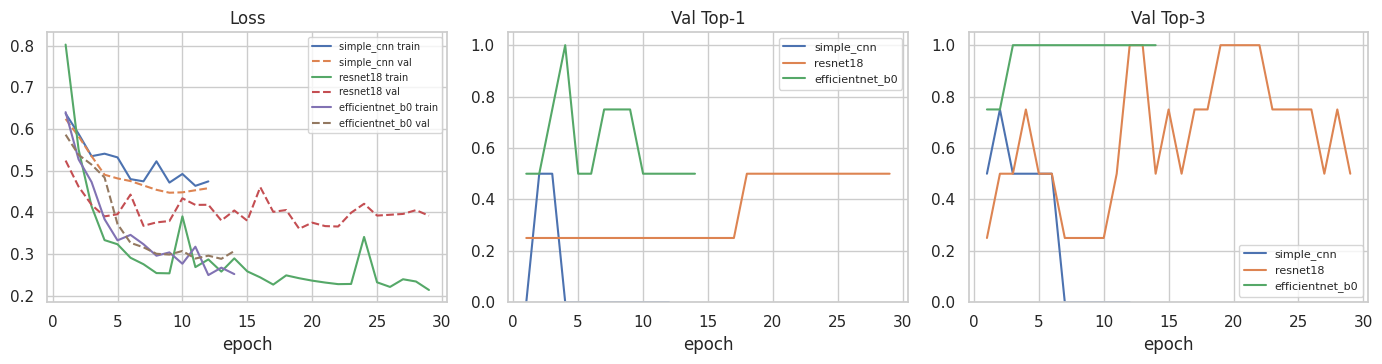

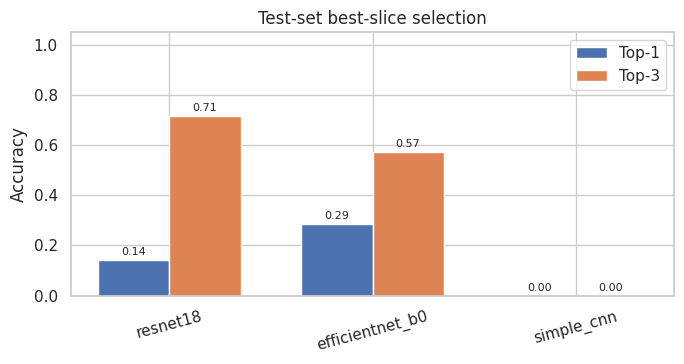

In [12]:
# Training curves
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for name, hist in histories.items():
    axes[0].plot(hist["epoch"], hist["train_loss"], label=f"{name} train")
    axes[0].plot(hist["epoch"], hist["val_loss"], linestyle="--", label=f"{name} val")
    axes[1].plot(hist["epoch"], hist["val_top1"], label=name)
    axes[2].plot(hist["epoch"], hist["val_top3"], label=name)

axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend(fontsize=7)
axes[1].set_title("Val Top-1"); axes[1].set_xlabel("epoch"); axes[1].set_ylim(0, 1.05); axes[1].legend(fontsize=8)
axes[2].set_title("Val Top-3"); axes[2].set_xlabel("epoch"); axes[2].set_ylim(0, 1.05); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "training_curves.png", dpi=140, bbox_inches="tight")
plt.show()

# Metric comparison bar chart
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(results_df))
w = 0.35
ax.bar(x - w/2, results_df["test_top1_acc"], width=w, label="Top-1")
ax.bar(x + w/2, results_df["test_top3_acc"], width=w, label="Top-3")
ax.set_xticks(x)
ax.set_xticklabels(results_df["model"], rotation=15)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accuracy")
ax.set_title("Test-set best-slice selection")
ax.legend()
for i, r in results_df.reset_index(drop=True).iterrows():
    ax.text(i - w/2, r["test_top1_acc"] + 0.02, f"{r['test_top1_acc']:.2f}", ha="center", fontsize=8)
    ax.text(i + w/2, r["test_top3_acc"] + 0.02, f"{r['test_top3_acc']:.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "test_metrics_bars.png", dpi=140, bbox_inches="tight")
plt.show()

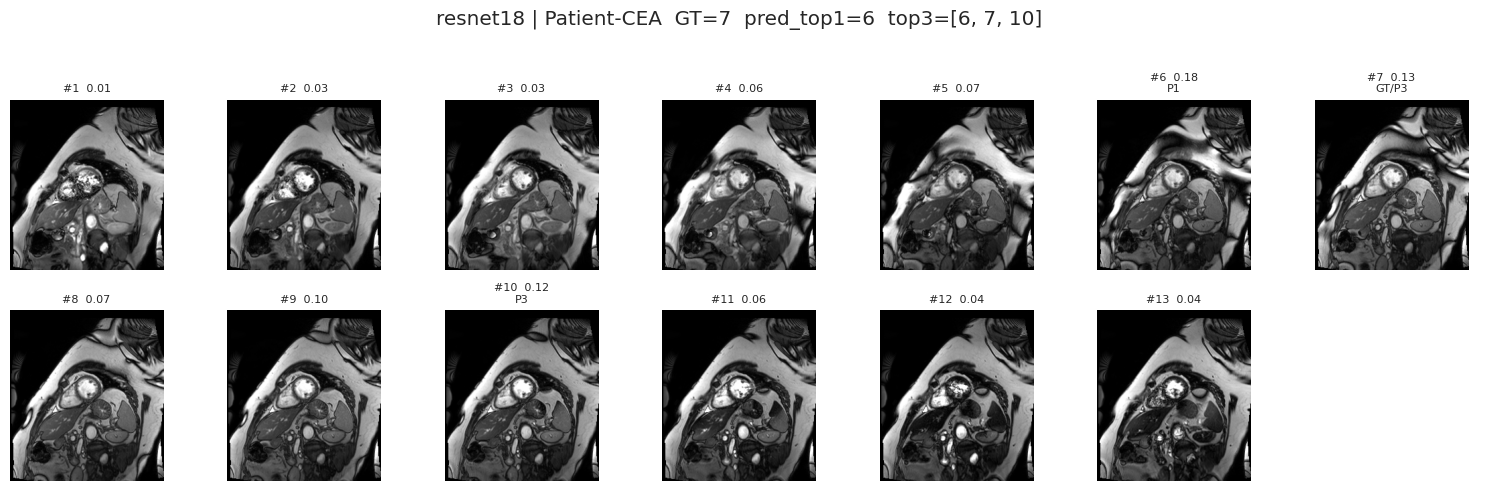

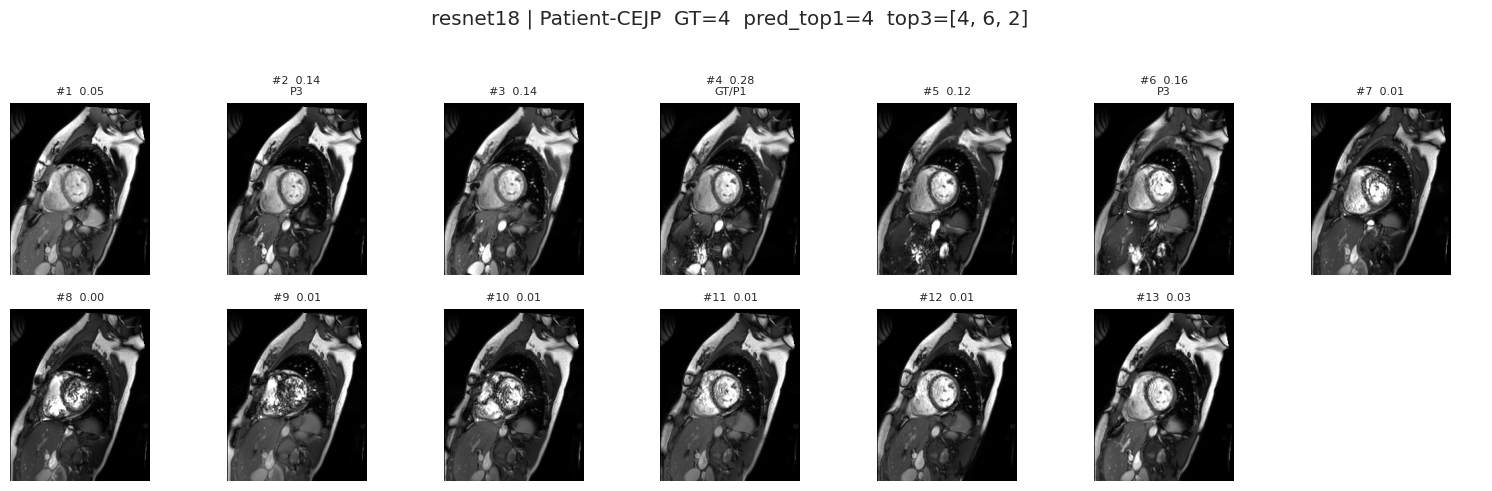

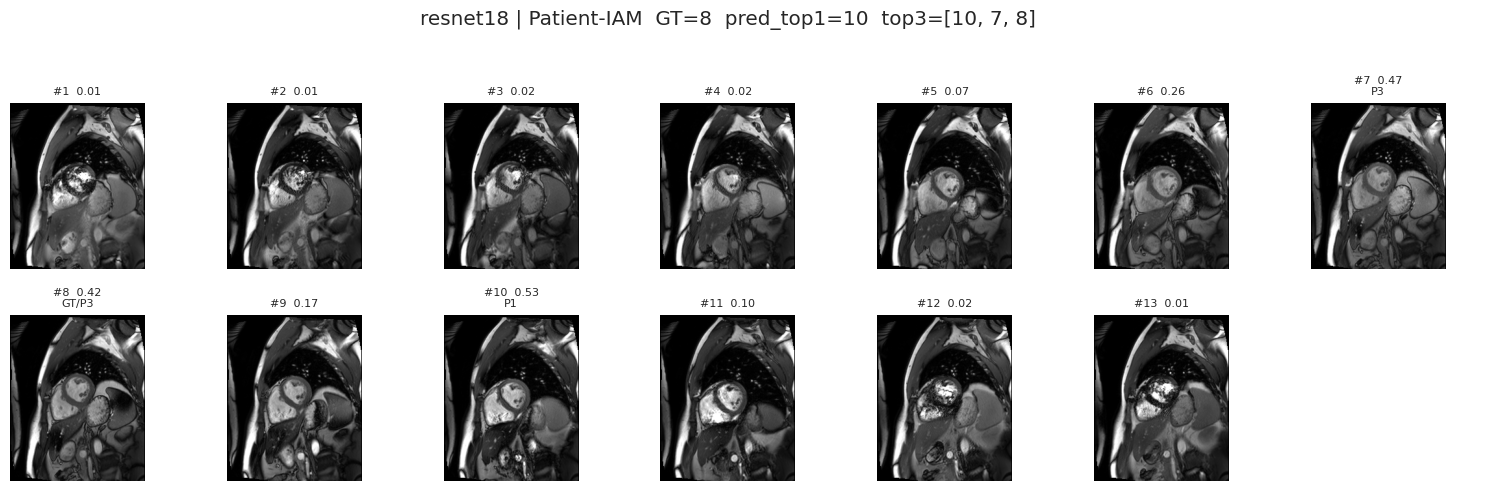

In [13]:
# Visualize best model's predictions on a few test patients
best_name = results_df.iloc[0]["model"]
best_model = trained_models[best_name]
pred_all_test = predict_frame(best_model, test_df, eval_tf)

show_pids = sorted(test_pids)[:3]
for pid in show_pids:
    sub = pred_all_test[pred_all_test["patient_id"] == pid].sort_values("instance_no")
    gt = int(sub["gt_image_no"].iloc[0])
    ranked = sub.sort_values("score", ascending=False)["instance_no"].tolist()
    top3 = ranked[:3]

    paths = index_df[index_df["patient_id"] == pid].set_index("instance_no")["path"]
    n = len(sub)
    cols = min(7, n)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.4 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, (_, r) in zip(axes, sub.iterrows()):
        arr = load_dicom_image(paths.loc[int(r["instance_no"])])
        ax.imshow(arr, cmap="gray")
        inst = int(r["instance_no"])
        flags = []
        if inst == gt:
            flags.append("GT")
        if inst == ranked[0]:
            flags.append("P1")
        elif inst in top3:
            flags.append("P3")
        title = f"#{inst}  {r['score']:.2f}"
        if flags:
            title += "\n" + "/".join(flags)
        ax.set_title(title, fontsize=8)
        color = "lime" if inst == gt else ("dodgerblue" if inst == ranked[0] else ("orange" if inst in top3 else "0.3"))
        for spine in ax.spines.values():
            spine.set_color(color)
            spine.set_linewidth(2.2)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(f"{best_name} | {pid}  GT={gt}  pred_top1={ranked[0]}  top3={top3}", y=1.02)
    plt.tight_layout()
    plt.show()

## 10. Optional — 5-fold patient CV (more reliable with n=26)

Set `cfg.use_kfold = True` in the config cell and re-run from there, **or** flip the flag below and run this section.

In [14]:
RUN_KFOLD = True  # change to True to run

if RUN_KFOLD:
    # Use one transfer model for CV to keep runtime reasonable
    cv_model_name = "resnet18"
    patient_ids = np.array(labels_df["patient_id"].tolist())
    y_strat = pd.qcut(labels_df["gt_image_no"], q=3, duplicates="drop").astype(str).values

    skf = StratifiedKFold(n_splits=cfg.n_folds, shuffle=True, random_state=cfg.seed)
    fold_rows = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(patient_ids, y_strat), 1):
        tr_p = patient_ids[tr_idx].tolist()
        te_p = patient_ids[te_idx].tolist()
        # Split train further into fit/val
        if len(tr_p) >= 5:
            tr_p2, va_p = train_test_split(tr_p, test_size=0.2, random_state=cfg.seed + fold)
        else:
            tr_p2, va_p = tr_p, tr_p[:1]

        fit = index_df[index_df["patient_id"].isin(tr_p2)].reset_index(drop=True)
        val = index_df[index_df["patient_id"].isin(va_p)].reset_index(drop=True)
        te = index_df[index_df["patient_id"].isin(te_p)].reset_index(drop=True)

        model, _ = train_one_model(cv_model_name, fit, val, tag=f"fold{fold}")
        metrics = patient_ranking_metrics(predict_frame(model, te, eval_tf))
        fold_rows.append({
            "fold": fold,
            "model": cv_model_name,
            "top1_acc": metrics["top1_acc"],
            "top3_acc": metrics["top3_acc"],
            "mae": metrics["mae"],
            "n_test": metrics["n_patients"],
        })
        print(f"Fold {fold}: Top1={metrics['top1_acc']:.3f} Top3={metrics['top3_acc']:.3f}")
        del model
        torch.cuda.empty_cache() if DEVICE.type == "cuda" else None

    cv_df = pd.DataFrame(fold_rows)
    cv_df.to_csv(OUT_DIR / "experiment1_kfold_results.csv", index=False)
    print("\n=== K-fold summary ===")
    display(cv_df)
    print(cv_df[["top1_acc", "top3_acc", "mae"]].agg(["mean", "std"]))
else:
    print("K-fold skipped. Set RUN_KFOLD = True (or cfg.use_kfold = True) to enable.")


Training: resnet18 fold1
Epoch 01/40  tr=0.5803 va=0.3994  Top1=0.250 Top3=0.750 MAE=2.00  *best*
Epoch 02/40  tr=0.4042 va=0.3656  Top1=0.500 Top3=0.750 MAE=0.75  *best*
Epoch 03/40  tr=0.3516 va=0.4097  Top1=0.000 Top3=1.000 MAE=2.25  *best*
Epoch 04/40  tr=0.3269 va=0.3456  Top1=0.250 Top3=1.000 MAE=2.00  *best*
Epoch 05/40  tr=0.3066 va=0.3469  Top1=0.500 Top3=1.000 MAE=1.50  *best*
Epoch 06/40  tr=0.2732 va=0.3167  Top1=0.750 Top3=1.000 MAE=0.25  *best*
Epoch 10/40  tr=0.2515 va=0.3378  Top1=0.500 Top3=0.750 MAE=1.25
Epoch 15/40  tr=0.2372 va=0.3396  Top1=0.500 Top3=0.750 MAE=1.25
Early stopping at epoch 16
Saved: /kaggle/working/exp1_outputs/resnet18_fold1_best.pt
Fold 1: Top1=0.333 Top3=0.667

Training: resnet18 fold2
Epoch 01/40  tr=0.6267 va=0.4677  Top1=0.000 Top3=0.600 MAE=1.20  *best*
Epoch 03/40  tr=0.3504 va=0.3660  Top1=0.000 Top3=0.800 MAE=1.20  *best*
Epoch 05/40  tr=0.2805 va=0.4670  Top1=0.000 Top3=1.000 MAE=1.00  *best*
Epoch 07/40  tr=0.2799 va=0.3277  Top1=0.200 

,fold,model,top1_acc,top3_acc,mae,n_test
0,1,resnet18,0.333333,0.666667,1.333333,6
1,2,resnet18,0.200000,0.600000,2.000000,5
2,3,resnet18,0.200000,0.400000,1.200000,5
3,4,resnet18,0.400000,0.600000,1.000000,5
4,5,resnet18,0.000000,0.800000,1.200000,5


      top1_acc  top3_acc       mae
mean  0.226667  0.613333  1.346667
std   0.153478  0.144530  0.384130


## 11. Chance baselines (for context)

With ~13 slices, random Top-1 ≈ 1/13 ≈ **7.7%**, random Top-3 ≈ 3/13 ≈ **23%**.  
Always picking the middle slice (image 7, often 0 Hz) is a stronger naïve baseline.

In [15]:
def baseline_metrics(frame: pd.DataFrame, strategy: str) -> dict:
    rows = []
    mode_gt = int(labels_df[labels_df["patient_id"].isin(train_pids)]["gt_image_no"].mode().iloc[0])
    for pid, g in frame.groupby("patient_id"):
        inst = sorted(g["instance_no"].tolist())
        gt = int(g["gt_image_no"].iloc[0])
        if strategy == "center":
            pred = inst[len(inst) // 2]
        elif strategy == "mode_train":
            pred = mode_gt if mode_gt in inst else inst[len(inst) // 2]
        else:
            raise ValueError(strategy)
        # For top-3 of a single-guess baseline: pred + two nearest neighbors
        neighbors = sorted(inst, key=lambda i: (abs(i - pred), i))
        top3 = neighbors[: min(3, len(neighbors))]
        rows.append({
            "top1": int(pred == gt),
            "top3": int(gt in top3),
            "mae": abs(pred - gt),
        })
    rdf = pd.DataFrame(rows)
    return {"top1_acc": float(rdf["top1"].mean()), "top3_acc": float(rdf["top3"].mean()), "mae": float(rdf["mae"].mean())}


# Analytical random expectation on test patients
ns = test_df.groupby("patient_id").size().values
rand_top1 = float(np.mean(1 / ns))
rand_top3 = float(np.mean([min(3, n) / n for n in ns]))

center = baseline_metrics(test_df, "center")
mode_b = baseline_metrics(test_df, "mode_train")

baseline_df = pd.DataFrame([
    {"model": "random (expected)", "test_top1_acc": rand_top1, "test_top3_acc": rand_top3, "test_mae": np.nan},
    {"model": "center slice", "test_top1_acc": center["top1_acc"], "test_top3_acc": center["top3_acc"], "test_mae": center["mae"]},
    {"model": "train-mode GT", "test_top1_acc": mode_b["top1_acc"], "test_top3_acc": mode_b["top3_acc"], "test_mae": mode_b["mae"]},
])

compare_df = pd.concat([results_df, baseline_df], ignore_index=True)
compare_df.to_csv(OUT_DIR / "experiment1_with_baselines.csv", index=False)
display(compare_df)
print(f"\nArtifacts written to: {OUT_DIR}")


,model,test_top1_acc,test_top3_acc,test_mae,n_test_patients
0,resnet18,0.142857,0.714286,1.000000,7.0
1,efficientnet_b0,0.285714,0.571429,1.285714,7.0
2,simple_cnn,0.000000,0.000000,4.571429,7.0
3,random (expected),0.086342,0.259027,NaN,NaN
4,center slice,0.142857,0.428571,1.571429,NaN
5,train-mode GT,0.142857,0.571429,1.428571,NaN



Artifacts written to: /kaggle/working/exp1_outputs


---
### Notes / next experiments
- Soft labels (`sigma=1`) teach the model that slices next to the GT are also relatively good — useful for Top-3.
- With only 26 patients, expect high variance across splits; enable **5-fold CV** for a stabler estimate.
- Possible follow-ups: ordinal regression on frequency offset, siamese pairwise ranking, or stacking all slices as a multi-channel / sequence input.
- Outputs: `exp1_outputs/*_best.pt`, `experiment1_test_results.csv`, plots.